In [2]:
# Your first Python code cell goes here
print("Hello, GitHub Notebook!")

Hello, GitHub Notebook!


In [3]:
# Load data from Hugging face
from datasets import load_dataset
dataset = load_dataset("maartengr/arxiv_nlp")["train"]

# extract metadata

abstracts = dataset["Abstracts"]
titles = dataset["Titles"]

README.md:   0%|          | 0.00/617 [00:00<?, ?B/s]

data.csv: reconstructing file:   0%|          |  0.00B / 53.2MB            

data.csv: downloading bytes:           |  0.00B            

Generating train split: 0 examples [00:00, ? examples/s]

In [4]:
from sentence_transformers import SentenceTransformer

# Create an embedding for each abstract
embedding_model = SentenceTransformer("thenlper/gte-small")
embeddings = embedding_model.encode(abstracts, show_progress_bar = True)

# embeddings shape
embeddings.shape

modules.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/68.1k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/583 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 66.7MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1405 [00:00<?, ?it/s]

(44949, 384)

In [5]:
from umap import UMAP

# reduce the input embeddings from 384 dim to 5 dim

umap_model = UMAP(
    n_components=5, min_dist = 0.0, metric = 'cosine', random_state = 42
    )

reduced_embeddings = umap_model.fit_transform(embeddings)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [6]:
from hdbscan import HDBSCAN

# we fit the model and extract the clusters
hdbscan_model = HDBSCAN(min_cluster_size = 50,
                        metric = 'euclidean',
                        cluster_selection_method = "eom",
                        ).fit(reduced_embeddings)

clusters = hdbscan_model.labels_


# How many clusters did we generate?

len(set(clusters))



158

In [7]:
import numpy as np

# Print first three documents in cluster 0

cluster = 0

for index in np.where(clusters == cluster)[0][:3]:
  print(abstracts[index][:300] + "... \n")

  This works aims to design a statistical machine translation from English text
to American Sign Language (ASL). The system is based on Moses tool with some
modifications and the results are synthesized through a 3D avatar for
interpretation. First, we translate the input text to gloss, a written fo... 

  Researches on signed languages still strongly dissociate lin- guistic issues
related on phonological and phonetic aspects, and gesture studies for
recognition and synthesis purposes. This paper focuses on the imbrication of
motion and meaning for the analysis, synthesis and evaluation of sign lang... 

  Modern computational linguistic software cannot produce important aspects of
sign language translation. Using some researches we deduce that the majority of
automatic sign language translation systems ignore many aspects when they
generate animation; therefore the interpretation lost the truth inf... 



In [8]:
import pandas as pd

# Reduce 384-dimensional embeddings to two dimensions for easier visualization

reduced_embeddings = UMAP(
    n_components = 2,
    min_dist = 0.0,
    metric = "cosine",
).fit_transform(embeddings)

# Create dataframe

df = pd.DataFrame(reduced_embeddings, columns = ["x", "y"])
df["title"] = titles
df["cluster"] = [str(c) for c in clusters]

# Select outliers and non-outliers(clusters)

to_plot = df.loc[df.cluster != "-1", :]
outliers = df.loc[df.cluster == "-1", :]


(np.float64(-8.49120545387268),
 np.float64(11.095458269119263),
 np.float64(-8.301298546791077),
 np.float64(11.402473378181458))

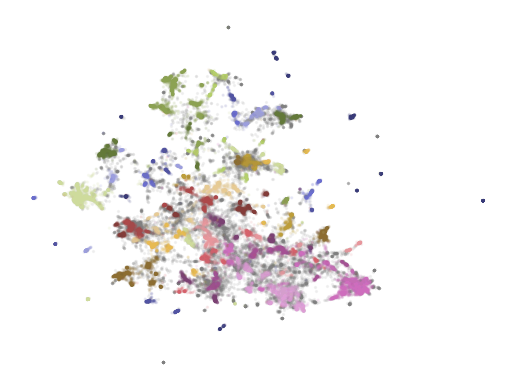

In [9]:
import matplotlib.pyplot as plt

# Plot outliers and non-outliers separately
plt.scatter(outliers.x, outliers.y, alpha = 0.08, s=2, c="grey")

plt.scatter(to_plot.x,
            to_plot.y,
            c = to_plot.cluster.astype(int),
            alpha=0.1,
            s = 2,
            cmap = 'tab20b',
            )
plt.axis('off')

In [12]:
pip install bertopic

In [37]:
from bertopic import BERTopic

# Train our model with our previously defined models

topic_model = BERTopic(
    embedding_model = embedding_model,
    umap_model = umap_model,
    hdbscan_model = hdbscan_model,
    verbose = True,
).fit(abstracts, embeddings)


topic_model.get_topic_info()

2026-11-03 19:14:05,778 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-03 19:15:25,801 - BERTopic - Dimensionality - Completed ✓
2026-11-03 19:15:25,805 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-03 19:15:36,595 - BERTopic - Cluster - Completed ✓
2026-11-03 19:15:36,618 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-03 19:15:45,623 - BERTopic - Representation - Completed ✓


,Topic,Count,Name,Representation,Representative_Docs
0,-1,15047,-1_the_of_and_to,"[the, of, and, to, in, we, for, that, language...",[ The availability of different pre-trained s...
1,0,1641,0_speech_asr_recognition_end,"[speech, asr, recognition, end, acoustic, spea...","[ Recently, masked prediction pre-training ha..."
2,1,1573,1_medical_clinical_biomedical_patient,"[medical, clinical, biomedical, patient, healt...",[ Various deep learning algorithms have been ...
3,2,1012,2_translation_nmt_machine_neural,"[translation, nmt, machine, neural, bleu, engl...",[ Monolingual data has been demonstrated to b...
4,3,894,3_summarization_summaries_summary_abstractive,"[summarization, summaries, summary, abstractiv...",[ Evaluation of text summarization approaches...
...,...,...,...,...,...
153,152,54,152_tokenization_tokenizer_subword_tokenizers,"[tokenization, tokenizer, subword, tokenizers,...",[ Subword tokenization has become the de-fact...
154,153,54,153_mixed_code_sentiment_english,"[mixed, code, sentiment, english, mixing, anal...",[ The usage of more than one language in the ...
155,154,53,154_opinion_reviews_summaries_summarization,"[opinion, reviews, summaries, summarization, r...",[ When faced with a large number of product r...
156,155,53,155_gans_gan_adversarial_generation,"[gans, gan, adversarial, generation, generativ...",[ Text generation is of particular interest i...


In [38]:
topic_model.get_topic(1)

[('medical', np.float64(0.0206633549188221)),
 ('clinical', np.float64(0.019770670594167095)),
 ('biomedical', np.float64(0.01368720633635237)),
 ('patient', np.float64(0.009627469509279892)),
 ('health', np.float64(0.008298932983271246)),
 ('notes', np.float64(0.007930352864273202)),
 ('patients', np.float64(0.006471805084581499)),
 ('healthcare', np.float64(0.006375801245394668)),
 ('and', np.float64(0.006247012732028427)),
 ('drug', np.float64(0.005969813624536975))]

In [39]:
topic_model.find_topics("Clinical")

([1, 83, 151, -1, 54],
 [np.float64(0.85601443390836),
  np.float64(0.8350805167613866),
  np.float64(0.8192208659587814),
  np.float64(0.8188834930747332),
  np.float64(0.8158862147274173)])

In [40]:
topic_model.get_topic(87)

[('amr', np.float64(0.10351673104798413)),
 ('meaning', np.float64(0.0305461969230437)),
 ('parsing', np.float64(0.02142525981984832)),
 ('smatch', np.float64(0.021186946034818823)),
 ('graph', np.float64(0.020458715128737575)),
 ('abstract', np.float64(0.01869666237066297)),
 ('parser', np.float64(0.01786291980443577)),
 ('representation', np.float64(0.015111489351304509)),
 ('graphs', np.float64(0.013724579361254605)),
 ('amrs', np.float64(0.013684793677598107))]

In [41]:
# Visualize topics and documents

fig = topic_model.visualize_documents(
    titles,
    reduced_embeddings = reduced_embeddings,
    width = 1200,
    hide_annotations = True
)

# Update fonts of legend for easier visualization
fig.update_layout(font = dict(size=16))

In [42]:
# Visualize barchart with ranked keywords
topic_model.visualize_barchart()

# Visualize relationships between topics
topic_model.visualize_heatmap(n_clusters = 30)

# visualize the potential hierarchical structure of topics
topic_model.visualize_hierarchy()

In [43]:
# save original representations

from copy import deepcopy
original_topics = deepcopy(topic_model.topic_representations_)

In [44]:
def topic_differences(model, original_topics, nr_topics = 5):
  """Show the differences in topic representations between two models"""
  df = pd.DataFrame(columns = ["Topic", "Original", "Updated"])

  for topic in range(nr_topics):

    # Extract top 5 words per topic per model
    og_words = " | ".join(list(zip(*original_topics[topic]))[0][:5])
    new_words = " | ".join(list(zip(*model.get_topic(topic)))[0][:5])

    df.loc[len(df)] = [topic, og_words, new_words]

  return df

In [45]:
from bertopic.representation import KeyBERTInspired

# Update out topic representation using KeyBERTInspired
representation_model = KeyBERTInspired()
topic_model.update_topics(abstracts, representation_model=representation_model)

# Show topic differences
topic_differences(topic_model, original_topics)

,Topic,Original,Updated
0,0,speech | asr | recognition | end | acoustic,phonetic | speech | encoder | transcription | ...
1,1,medical | clinical | biomedical | patient | he...,nlp | clinical | ehr | ehrs | medicine
2,2,translation | nmt | machine | neural | bleu,translation | translate | translations | trans...
3,3,summarization | summaries | summary | abstract...,summarization | summarizers | summaries | summ...
4,4,hate | offensive | speech | detection | toxic,hate | hateful | language | offensive | languages


In [46]:
from bertopic.representation import MaximalMarginalRelevance

# Update out topic representations to MaximalMarginalRelevance

representation_model = MaximalMarginalRelevance(diversity = 0.2)

topic_model.update_topics(abstracts, representation_model = representation_model)

# Show topic differences
topic_differences(topic_model, original_topics)

,Topic,Original,Updated
0,0,speech | asr | recognition | end | acoustic,speech | asr | wer | audio | training
1,1,medical | clinical | biomedical | patient | he...,medical | clinical | biomedical | patient | pa...
2,2,translation | nmt | machine | neural | bleu,translation | nmt | neural | parallel | languages
3,3,summarization | summaries | summary | abstract...,summarization | summaries | abstractive | sent...
4,4,hate | offensive | speech | detection | toxic,hate | offensive | toxic | abusive | hateful


In [31]:
from transformers import pipeline
from bertopic.representation import TextGeneration

prompt = """I have a topic that contains the following documents:
[DOCUMENT]

The topic is described by the following keywords: '[KEYWORDS]'.

Based on the documents and keywords, what is this topic about?
"""

# Using the lightweight Qwen2.5-1.5B-Instruct model for text-generation
generator = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct", max_new_tokens=50)

representation_model = TextGeneration(
    generator, prompt=prompt, doc_length=50, tokenizer="whitespace"
)

topic_model.update_topics(abstracts, representation_model=representation_model)

# Show topic differences
topic_differences(topic_model, original_topics)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

100%|██████████| 158/158 [11:17<00:00,  4.29s/it]


,Topic,Original,Updated
0,0,speech | asr | recognition | end | acoustic,This appears to be a topic related to Automati...
1,1,medical | clinical | biomedical | patient | he...,This topic appears to be related to medical re...
2,2,translation | nmt | machine | neural | bleu,This appears to be a topic related to natural ...
3,3,summarization | summaries | summary | abstract...,This appears to be a topic related to summariz...
4,4,hate | offensive | speech | detection | toxic,This topic appears to be related to detecting ...


In [50]:
fig=topic_model.visualize_document_datamap(
    titles,
    topics=list(range(10)),
    reduced_embeddings=reduced_embeddings,
    width=1200,
    label_font_size = 11,
    label_wrap_width=20,
    use_mediods=True,
    show_legend=True,
    )

fig.update_layout(font=dict(size=16))


NameError: name 'datamapplot' is not defined